# Smart Watering: Decision Tree
ICS 3202 | CAT 2

| Presenter | Part |
|---|---|
| Ian | Data and cleaning |
| Devyan | Labels and exploration |
| Alfred | Training and results |


## Project goal
Predict end-of-day watering need: **1 = water, 0 = wait**. Use past weather for outdoor Nairobi plants.

**Weather is real; plants and labels are simulated.**


## 1. Ian: Data and cleaning
### 1.1 Our approach
Supervised binary classification using a **Decision Tree**.


In [1]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
VERSIONS = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "requests", "joblib"]}


### 1.2 Load the weather data
Nairobi ERA5, **2015-2025**. Verified data is included; no API download needed.


In [2]:
#@title Load the verified Nairobi weather snapshot
URL = "https://archive-api.open-meteo.com/v1/archive"
PARAMS = {"latitude": -1.2921, "longitude": 36.8219,
          "start_date": "2015-01-01", "end_date": "2025-12-31",
          "daily": "temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max",
          "timezone": "Africa/Nairobi", "models": "era5",
          "temperature_unit": "celsius", "wind_speed_unit": "kmh", "precipitation_unit": "mm"}

import base64, gzip, io
# Verified ERA5 snapshot, downloaded 27 October 2026. No API call is needed.
WEATHER_GZIP_BASE64 = (
    '...'
)
BUNDLED_PROVENANCE = {'source': 'https://archive-api.open-meteo.com/v1/archive', 'request': {'latitude': -1.2921, 'longitude': 36.8219, 'start_date': '2015-01-01', 'end_date': '2025-12-31', 'daily': 'temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max', 'timezone': 'Africa/Nairobi', 'models': 'era5', 'temperature_unit': 'celsius', 'wind_speed_unit': 'kmh', 'precipitation_unit': 'mm'}, 'resolved_url': 'https://archive-api.open-meteo.com/v1/archive?latitude=-1.2921&longitude=36.8219&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_max%2Ctemperature_2m_min%2Ctemperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum%2Cet0_fao_evapotranspiration%2Cwind_speed_10m_max&timezone=Africa%2FNairobi&models=era5&temperature_unit=celsius&wind_speed_unit=kmh&precipitation_unit=mm', 'retrieved_utc': '2026-10-27T18:08:33.368175+00:00', 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'temperature_2m_mean': '°C', 'relative_humidity_2m_mean': '%', 'precipitation_sum': 'mm', 'et0_fao_evapotranspiration': 'mm', 'wind_speed_10m_max': 'km/h'}, 'location': {'latitude': -1.25, 'longitude': 36.75, 'elevation': 1668.0, 'timezone': 'Africa/Nairobi'}, 'sha256': 'b5d3ab20d074e95a4b76428d4f21974494224c0c9e6aaac9aeaf036a67dfcebb'}

weather_bytes = gzip.decompress(base64.b64decode(WEATHER_GZIP_BASE64))
assert hashlib.sha256(weather_bytes).hexdigest() == BUNDLED_PROVENANCE["sha256"], "Bundled weather checksum mismatch."
assert BUNDLED_PROVENANCE["request"] == PARAMS, "Bundled weather request mismatch."
raw = pd.read_csv(io.BytesIO(weather_bytes))
provenance = BUNDLED_PROVENANCE.copy()
RAW_PATH = Path("nairobi_era5_daily_2015_2025.csv")
META_PATH = Path("weather_provenance.json")
RAW_PATH.write_bytes(weather_bytes)
META_PATH.write_text(json.dumps(provenance, indent=2))
print("Loaded verified Nairobi ERA5 snapshot. No weather download required.")
print("Source:", provenance["source"], "| requested model:", PARAMS["models"])
print("Location:", provenance["location"])
print("Raw shape:", raw.shape, "| SHA256:", provenance["sha256"])
display(raw.head())


Loaded verified Nairobi ERA5 snapshot. No weather download required.
Source: https://archive-api.open-meteo.com/v1/archive | requested model: era5
Location: {'latitude': -1.25, 'longitude': 36.75, 'elevation': 1668.0, 'timezone': 'Africa/Nairobi'}
Raw shape: (4018, 8) | SHA256: b5d3ab20d074e95a4b76428d4f21974494224c0c9e6aaac9aeaf036a67dfcebb


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,et0_fao_evapotranspiration,wind_speed_10m_max
0,2015-01-01,28.0,12.6,20.3,52,0.0,5.84,18.3
1,2015-01-02,28.6,11.9,20.8,42,0.0,6.66,19.1
2,2015-01-03,29.5,12.7,20.9,40,0.0,6.22,18.3
3,2015-01-04,30.2,13.3,21.5,40,0.0,5.62,12.6
4,2015-01-05,29.8,13.8,21.8,49,0.0,4.71,11.9


### 1.3 Fix the format and check missing values
Convert types, sort dates and check missing values. Missing rain is not zero rain.


In [3]:
print(raw.dtypes)
weather = raw.rename(columns={"time": "date", "temperature_2m_max": "temp_max",
    "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_mean",
    "relative_humidity_2m_mean": "humidity_mean", "precipitation_sum": "rain",
    "et0_fao_evapotranspiration": "et0", "wind_speed_10m_max": "wind_max"}).copy()
weather["date"] = pd.to_datetime(weather["date"], errors="raise")
num_cols = ["temp_max", "temp_min", "temp_mean", "humidity_mean", "rain", "et0", "wind_max"]
weather[num_cols] = weather[num_cols].apply(pd.to_numeric, errors="raise")
weather = weather.sort_values("date").reset_index(drop=True)
print("After renaming, conversion and sorting:", weather.shape)
display(weather.dtypes)
print("Summary statistics:")
display(weather.describe().round(2))

print(weather.isna().sum())
assert not weather.isna().any().any(), "Missing data: resolve from the source before simulation. Missing rain is not zero rain."
assert np.isfinite(weather[num_cols].to_numpy()).all(), "Non-finite weather values."
print("No missing values. No interpolation or zero-rain filling applied.")


time                              str
temperature_2m_max            float64
temperature_2m_min            float64
temperature_2m_mean           float64
relative_humidity_2m_mean       int64
precipitation_sum             float64
et0_fao_evapotranspiration    float64
wind_speed_10m_max            float64
dtype: object
After renaming, conversion and sorting: (4018, 8)


date             datetime64[us]
temp_max                float64
temp_min                float64
temp_mean               float64
humidity_mean             int64
rain                    float64
et0                     float64
wind_max                float64
dtype: object

Summary statistics:


,date,temp_max,temp_min,temp_mean,humidity_mean,rain,et0,wind_max
count,4018,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00
mean,2020-07-01 12:00:00,25.32,15.02,19.72,69.48,1.73,4.22,14.42
min,2015-01-01 00:00:00,17.00,8.20,15.40,35.00,0.00,1.19,4.50
25%,2017-10-01 06:00:00,23.70,14.00,18.70,63.00,0.00,3.34,11.30
50%,2020-07-01 12:00:00,25.40,15.20,19.80,70.00,0.30,4.17,14.20
75%,2023-04-01 18:00:00,27.00,16.20,20.70,76.00,1.40,5.04,17.50
max,2025-12-31 00:00:00,32.20,19.40,23.90,94.00,42.10,7.74,26.30
std,NaN,2.41,1.59,1.46,9.77,3.82,1.18,4.01


date             0
temp_max         0
temp_min         0
temp_mean        0
humidity_mean    0
rain             0
et0              0
wind_max         0
dtype: int64
No missing values. No interpolation or zero-rain filling applied.


### 1.4 Check duplicates, dates and ranges
Remove exact duplicates. Check calendar coverage and plausible ranges. Exclude minimum temperature after validation.


In [4]:
print("Duplicate dates:", int(weather["date"].duplicated().sum()))
# Remove only exact duplicate rows. Conflicting readings for the same date need review.
before = len(weather)
weather = weather.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", before - len(weather))
assert not weather["date"].duplicated().any(), "Conflicting duplicate dates need source review."
full_range = pd.date_range(PARAMS["start_date"], PARAMS["end_date"], freq="D")
missing_days = full_range.difference(weather["date"])
extra_days = pd.DatetimeIndex(weather["date"]).difference(full_range)
print("Expected:", len(full_range), "Present:", len(weather), "Missing:", len(missing_days), "Extra:", len(extra_days))
assert len(missing_days) == len(extra_days) == 0, "Resolve calendar gaps before rolling features or simulation."

checks = {
    "temperature plausibility (-5 to 45 C)": weather[["temp_min", "temp_mean", "temp_max"]].apply(lambda x: x.between(-5, 45)).all(axis=1),
    "min <= mean <= max": (weather["temp_min"] <= weather["temp_mean"]) & (weather["temp_mean"] <= weather["temp_max"]),
    "humidity 0 to 100": weather["humidity_mean"].between(0, 100),
    "rain non-negative": weather["rain"] >= 0,
    "ET0 non-negative": weather["et0"] >= 0,
    "wind non-negative": weather["wind_max"] >= 0}
valid = pd.DataFrame(checks)
print("Rows flagged by each check:")
print((~valid).sum())
assert valid.all().all(), "Flagged rows require source review. Do not delete dates and silently bridge the gap."
print("All checks passed. Rows removed by range checks: 0")

# Irrelevant data: temp_min was only needed for the check above
weather = weather.drop(columns=["temp_min"])
print("Columns kept:", list(weather.columns))


Duplicate dates: 0
Exact duplicate rows removed: 0
Expected: 4018 Present: 4018 Missing: 0 Extra: 0
Rows flagged by each check:
temperature plausibility (-5 to 45 C)    0
min <= mean <= max                       0
humidity 0 to 100                        0
rain non-negative                        0
ET0 non-negative                         0
wind non-negative                        0
dtype: int64
All checks passed. Rows removed by range checks: 0
Columns kept: ['date', 'temp_max', 'temp_mean', 'humidity_mean', 'rain', 'et0', 'wind_max']


### 1.5 Check unusual values
Keep plausible outliers. An IQR flag alone does not indicate an error.


temp_mean          6
temp_max          20
humidity_mean     26
rain             566
et0                2
wind_max           0
dtype: int64


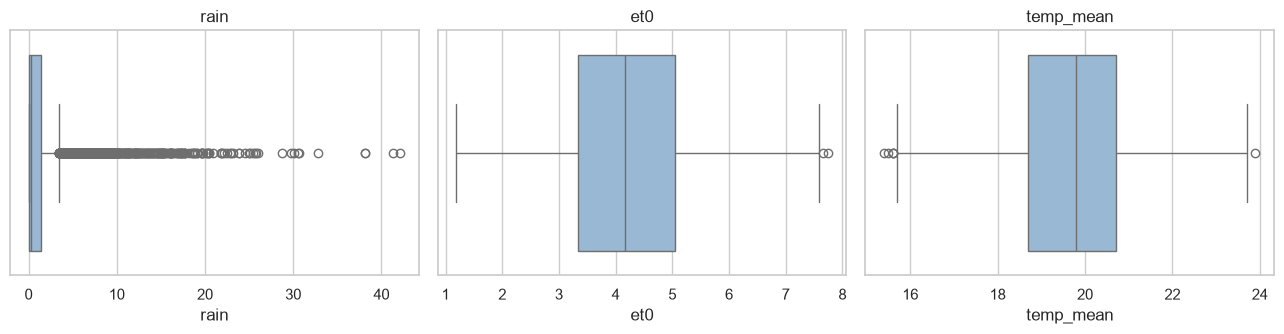

Cleaned weather: (4018, 7)
Dates: 2015-01-01 to 2025-12-31


In [5]:
# IQR rule: a value is an 'outlier' if it is more than 1.5 x IQR beyond the middle 50%
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_counts = weather[["temp_mean", "temp_max", "humidity_mean", "rain", "et0", "wind_max"]].apply(iqr_outliers)
print(outlier_counts)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["rain", "et0", "temp_mean"]):
    sns.boxplot(x=weather[col], ax=ax, color="#8fb8de")
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("Cleaned weather:", weather.shape)
print("Dates:", weather["date"].min().date(), "to", weather["date"].max().date())


### 1.6 Observation 1: Rainfall through the year
Compare monthly rainfall and ET0.


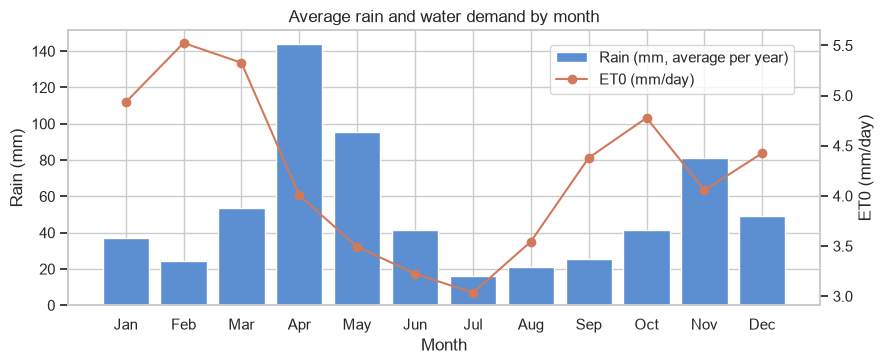

Observation 1: the wettest months are Apr, May, Nov, Mar, averaging 94 mm each, while the driest months are Feb, Aug, Jul at 20 mm each. ET0 (water demand) is highest in Feb (5.52 mm/day) and lowest in Jul (3.03 mm/day).


In [6]:
monthly = weather.assign(month=weather["date"].dt.month).groupby("month").agg(
    rain_mm_per_year=("rain", lambda s: s.sum() / weather["date"].dt.year.nunique()),
    et0_mm_per_day=("et0", "mean"))

fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(monthly.index, monthly["rain_mm_per_year"], color="#5b8fd1", label="Rain (mm, average per year)")
ax1.set_xlabel("Month"); ax1.set_ylabel("Rain (mm)")
ax1.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["et0_mm_per_day"], color="#d1795b", marker="o", label="ET0 (mm/day)")
ax2.set_ylabel("ET0 (mm/day)"); ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88)); plt.title("Average rain and water demand by month")
plt.tight_layout(); plt.show()

import calendar
month_name = lambda m: calendar.month_abbr[m]    # 3 -> 'Mar'
top = monthly["rain_mm_per_year"].sort_values(ascending=False)
print(f"Observation 1: the wettest months are {', '.join(month_name(m) for m in top.index[:4])}, averaging "
      f"{top.iloc[:4].mean():.0f} mm each, while the driest months are {', '.join(month_name(m) for m in top.index[-3:])} "
      f"at {top.iloc[-3:].mean():.0f} mm each. ET0 (water demand) is highest in {month_name(monthly['et0_mm_per_day'].idxmax())} "
      f"({monthly['et0_mm_per_day'].max():.2f} mm/day) and lowest in {month_name(monthly['et0_mm_per_day'].idxmin())} "
      f"({monthly['et0_mm_per_day'].min():.2f} mm/day).")


## 2. Devyan: Labels and exploration
### 2.1 Plant groups and individual variation
**20 simulated plants**, four per group. Hidden parameters generate labels; the model receives nominal group values.


In [7]:
plants = pd.DataFrame([
    # group,            example,              kc,   root_m, p,    schedule_days
    ("succulent",       "aloe, cactus",       0.20, 0.25,   0.70, 10),
    ("herb",            "rosemary, thyme",    0.30, 0.25,   0.60, 7),
    ("flowering",       "marigold, petunia",  0.50, 0.20,   0.50, 3),
    ("fern",            "Boston fern",        0.80, 0.20,   0.35, 3),
    ("leafy_vegetable", "sukuma wiki (kale)", 1.00, 0.30,   0.45, 2),
], columns=["group", "example", "kc", "root_m", "p", "schedule_days"])

# Nominal (textbook) values: this is all the app knows about a plant, from its species.
AVAILABLE_WATER = 0.14
plants["taw_mm"] = 1000 * AVAILABLE_WATER * plants["root_m"]
plants["threshold_mm"] = (plants["p"] * plants["taw_mm"]).round(1)

# Scenario: real plants of the same species differ (pot size, soil mix, sun, shade).
# We create several individual plants per group, each with its own TRUE values drawn
# around the nominal ones. Labels come from the true values; the model only sees nominal ones.
PLANTS_PER_GROUP = 4
rng = np.random.default_rng(RANDOM_STATE)
individuals = []
for g in plants.itertuples():
    for k in range(PLANTS_PER_GROUP):
        true_kc = g.kc * rng.uniform(0.8, 1.2)                 # +/- 20% water use
        true_aw = rng.uniform(0.10, 0.18)                      # soil holds 0.10-0.18 m3/m3
        true_root = g.root_m * rng.uniform(0.8, 1.2)           # +/- 20% root depth
        true_p = float(np.clip(g.p + rng.uniform(-0.1, 0.1), 0.2, 0.8))
        individuals.append({"plant_id": f"{g.group}_{k + 1}", "group": g.group,
                            "kc": g.kc, "threshold_mm": g.threshold_mm, "schedule_days": g.schedule_days,
                            "true_kc": round(true_kc, 3),
                            "true_threshold_mm": round(true_p * 1000 * true_aw * true_root, 1)})
individuals = pd.DataFrame(individuals)
display(plants)
display(individuals.head(8))
print(f"{len(individuals)} individual plants ({PLANTS_PER_GROUP} per group)")


,group,example,kc,root_m,p,schedule_days,taw_mm,threshold_mm
0,succulent,"aloe, cactus",0.2,0.25,0.70,10,35.0,24.5
1,herb,"rosemary, thyme",0.3,0.25,0.60,7,35.0,21.0
2,flowering,"marigold, petunia",0.5,0.20,0.50,3,28.0,14.0
3,fern,Boston fern,0.8,0.20,0.35,3,28.0,9.8
4,leafy_vegetable,sukuma wiki (kale),1.0,0.30,0.45,2,42.0,18.9


,plant_id,group,kc,threshold_mm,schedule_days,true_kc,true_threshold_mm
0,succulent_1,succulent,0.2,24.5,10,0.222,28.6
1,succulent_2,succulent,0.2,24.5,10,0.168,37.2
2,succulent_3,succulent,0.2,24.5,10,0.170,25.3
3,succulent_4,succulent,0.2,24.5,10,0.212,26.2
4,herb_1,herb,0.3,21.0,7,0.307,18.6
5,herb_2,herb,0.3,21.0,7,0.331,25.9
6,herb_3,herb,0.3,21.0,7,0.333,14.5
7,herb_4,herb,0.3,21.0,7,0.259,29.4


20 individual plants (4 per group)


### 2.2 Generate the labels
Label 1 when simulated deficit reaches the threshold. Watering resets deficit: **50% probability when needed, 5% otherwise**.

Inputs end yesterday. Warm-up: 30 days. Rain counter: capped at 30 days.


In [8]:
MIN_EFFECTIVE_RAIN = 2.0   # mm; smaller showers are ignored

w = weather[["date", "temp_mean", "temp_max", "humidity_mean", "wind_max", "rain", "et0"]].copy()
w["effective_rain"] = np.where(w["rain"] >= MIN_EFFECTIVE_RAIN, w["rain"], 0.0)

# Timing: the app decides at 7 a.m., before today's weather has happened.
# So every weather input is from YESTERDAY or the last 3 days, never today.
for col in ["temp_mean", "temp_max", "humidity_mean", "wind_max", "rain", "et0"]:
    w[f"{col}_yday"] = w[col].shift(1)
w["rain_last_3d"] = w["rain"].rolling(3, min_periods=1).sum().shift(1)
w["et0_last_3d"] = w["et0"].rolling(3, min_periods=1).sum().shift(1)
days_since_rain, counter = [], 0
for r in w["effective_rain"]:
    counter = 0 if r > 0 else counter + 1
    days_since_rain.append(counter)
w["days_since_rain"] = pd.Series(days_since_rain).shift(1).clip(upper=30)     # as of yesterday evening

# Behaviour: a real gardener does not water at the perfect moment.
# When a plant needs water, the gardener notices and waters it that day only half the time;
# the plant stays thirsty until they do. Sometimes they water out of habit anyway.
NOTICE_PROB = 0.5   # chance of watering on a day the plant needs it
HABIT_PROB = 0.05   # chance of watering on any other day
start = weather["date"].min()

def simulate(p):
    """Simulate one individual plant and one imperfect gardener over the whole weather history."""
    rng = np.random.default_rng(RANDOM_STATE + p.Index)     # fixed seed per plant, same every run
    deficit, dsw = 0.0, 0
    labels, dsw_list, deficits = [], [], []
    for et0, rain in zip(w["et0"], w["effective_rain"]):
        dsw += 1                                              # days since the gardener last watered (this morning)
        deficit = max(0.0, deficit + p.true_kc * et0 - rain)  # true soil dryness tonight
        needs = int(deficit >= p.true_threshold_mm)
        labels.append(needs); dsw_list.append(dsw); deficits.append(deficit)
        water_probability = NOTICE_PROB if needs else HABIT_PROB
        if rng.random() < water_probability:
            deficit, dsw = 0.0, 0                             # gardener waters
    out = w.copy()
    for col in ["plant_id", "group", "kc", "threshold_mm", "schedule_days", "true_kc", "true_threshold_mm"]:
        out[col] = getattr(p, col)
    out["days_since_watered"] = dsw_list
    out["deficit_mm"] = deficits              # for checking only; NOT a model feature
    out["water_today"] = labels
    # Fixed-calendar baseline for this plant: "water every N days", on its own fixed cycle
    day_number = (out["date"] - start).dt.days + 1
    out["calendar_pred"] = (day_number % p.schedule_days == 0).astype(int)
    return out

data = pd.concat([simulate(p) for p in individuals.itertuples()], ignore_index=True)
data = data[data["date"] >= start + pd.Timedelta(days=30)].reset_index(drop=True)   # warm-up
print("Modelling dataset shape:", data.shape)
print(f"Plant-days needing water: {data['water_today'].mean():.1%}")
data.head()


Modelling dataset shape: (79760, 28)
Plant-days needing water: 17.4%


,date,temp_mean,temp_max,humidity_mean,wind_max,rain,et0,effective_rain,temp_mean_yday,temp_max_yday,...,group,kc,threshold_mm,schedule_days,true_kc,true_threshold_mm,days_since_watered,deficit_mm,water_today,calendar_pred
0,2015-01-31,21.3,29.9,49,20.2,0.0,6.67,0.0,21.3,29.2,...,succulent,0.2,24.5,10,0.222,28.6,3,4.13586,0,0
1,2015-02-01,21.5,29.2,53,21.7,0.0,6.32,0.0,21.3,29.9,...,succulent,0.2,24.5,10,0.222,28.6,4,5.53890,0,0
2,2015-02-02,21.4,28.4,58,22.7,0.0,5.88,0.0,21.5,29.2,...,succulent,0.2,24.5,10,0.222,28.6,5,6.84426,0,0
3,2015-02-03,21.0,27.8,58,23.3,0.0,5.88,0.0,21.4,28.4,...,succulent,0.2,24.5,10,0.222,28.6,6,8.14962,0,0
4,2015-02-04,20.7,27.3,61,22.5,0.0,5.65,0.0,21.0,27.8,...,succulent,0.2,24.5,10,0.222,28.6,7,9.40392,0,0


### 2.3 Select the inputs
Select 12 weather, watering-history and plant features. Exclude hidden parameters, deficit, plant ID and target.


In [9]:
FEATURES = ["temp_mean_yday", "temp_max_yday", "humidity_mean_yday", "wind_max_yday",
            "rain_yday", "rain_last_3d", "et0_yday", "et0_last_3d",
            "days_since_rain", "days_since_watered", "kc", "threshold_mm"]
TARGET = "water_today"

# kc and threshold_mm are the NOMINAL species values (what the app knows), not the true ones
print("Missing values in features or target:", int(data[FEATURES + [TARGET]].isnull().sum().sum()))
print("Rows:", len(data), "| individual plants:", data["plant_id"].nunique(), "| groups:", data["group"].nunique())
for f in FEATURES:
    print(" -", f)

assert not data[FEATURES + [TARGET]].isna().any().any()
assert np.isfinite(data[FEATURES].to_numpy()).all()
assert not set(FEATURES) & {TARGET, "deficit_mm", "true_kc", "true_threshold_mm", "plant_id"}
assert data["days_since_rain"].between(0, 30).all()


Missing values in features or target: 0
Rows: 79760 | individual plants: 20 | groups: 5
 - temp_mean_yday
 - temp_max_yday
 - humidity_mean_yday
 - wind_max_yday
 - rain_yday
 - rain_last_3d
 - et0_yday
 - et0_last_3d
 - days_since_rain
 - days_since_watered
 - kc
 - threshold_mm


### 2.4 Observation 2: How often each group needs water
Check class balance across simulated groups.


Observation 2: overall, plants need watering on 17.4% of days. By group:
   succulent          0.9% of days (about every 117.3 days)
   herb               5.0% of days (about every 20.0 days)
   flowering         14.7% of days (about every 6.8 days)
   leafy_vegetable   26.6% of days (about every 3.8 days)
   fern              40.1% of days (about every 2.5 days)


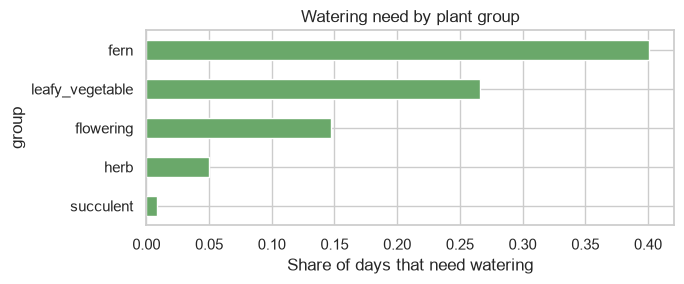

In [10]:
overall = data[TARGET].mean()
by_group = data.groupby("group")[TARGET].mean().sort_values()
print(f"Observation 2: overall, plants need watering on {overall:.1%} of days. By group:")
for g, v in by_group.items():
    print(f"   {g:16s} {v:6.1%} of days (about every {1/v:.1f} days)" if v > 0 else f"   {g:16s} never")

by_group.plot(kind="barh", color="#6aa86a", figsize=(7, 3))
plt.xlabel("Share of days that need watering"); plt.title("Watering need by plant group")
plt.tight_layout(); plt.show()


### 2.5 Observation 3: Watering labels by month
Compare monthly watering rates with rainfall.


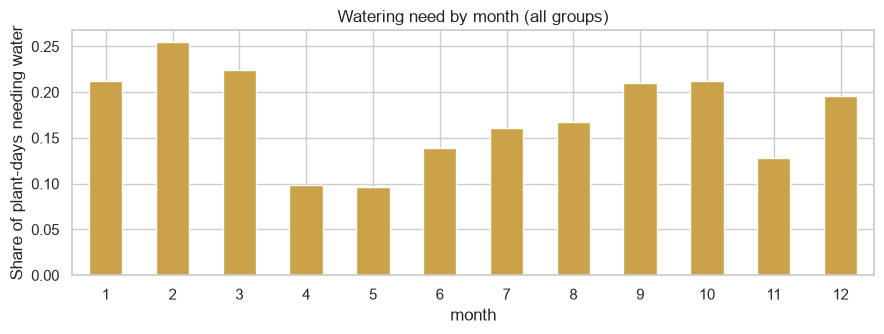

Observation 3: watering need peaks in Feb (25.5% of plant-days) and is lowest in May (9.6%). Correlation between monthly rain and monthly watering need: -0.70.


In [11]:
seasonal = data.assign(month=data["date"].dt.month).groupby("month")[TARGET].mean()
seasonal.plot(kind="bar", color="#c9a24a", figsize=(9, 3.5), rot=0)
plt.ylabel("Share of plant-days needing water"); plt.title("Watering need by month (all groups)")
plt.tight_layout(); plt.show()

print(f"Observation 3: watering need peaks in {month_name(seasonal.idxmax())} ({seasonal.max():.1%} of plant-days) "
      f"and is lowest in {month_name(seasonal.idxmin())} ({seasonal.min():.1%}). "
      f"Correlation between monthly rain and monthly watering need: "
      f"{np.corrcoef(monthly['rain_mm_per_year'], seasonal)[0, 1]:.2f}.")


### 2.6 Observation 4: Features linked to watering
Correlation describes association, not causation.


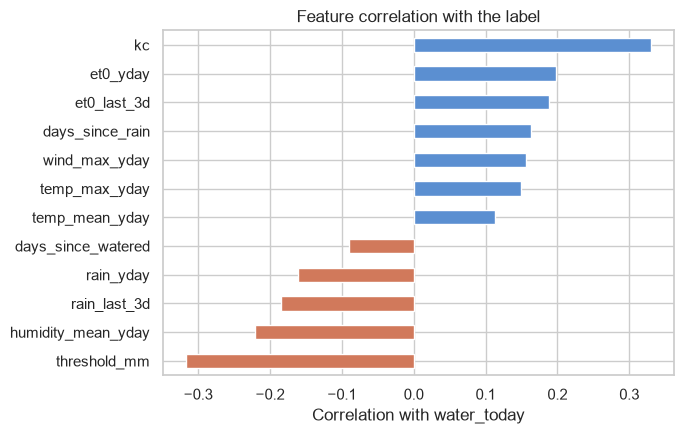

Observation 4: strongest positive links: kc (0.33), et0_yday (0.20), et0_last_3d (0.19)
               strongest negative links: threshold_mm (-0.32), humidity_mean_yday (-0.22), rain_last_3d (-0.18)


In [12]:
corr = data[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind="barh", color=["#d1795b" if v < 0 else "#5b8fd1" for v in corr], figsize=(7, 4.5))
plt.xlabel("Correlation with water_today"); plt.title("Feature correlation with the label")
plt.tight_layout(); plt.show()

print("Observation 4: strongest positive links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.tail(3)[::-1].items()))
print("               strongest negative links:", ", ".join(f"{k} ({v:.2f})" for k, v in corr.head(3).items()))


## 3. Alfred: Training and results
### 3.1 Main split: stratified random 80/20
Preserve class proportions. Shared plants and nearby dates can cross this split; future performance requires separate testing.


In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# Main evaluation (as specified in the supplied build bible): stratified random 80/20 split
train, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {len(train):,} rows, {y_train.mean():.1%} need water")
print(f"Test:  {len(test):,} rows, {y_test.mean():.1%} need water")


Train: 63,808 rows, 17.4% need water
Test:  15,952 rows, 17.4% need water


### 3.2 Fit the base tree and compare tuning
Depth-2, class-balanced baseline: intentionally limited for this demonstration. Use five-fold CV; keep the stronger tuned tree for comparison.


In [14]:
# Stratified 5-fold cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 20, 50, 100],
              "class_weight": [None, "balanced"]}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                           scoring="f1", cv=cv, n_jobs=2, return_train_score=True, error_score="raise")
tree_search.fit(X_train, y_train)
best = tree_search.best_index_
res = tree_search.cv_results_
print("Best settings:", tree_search.best_params_)
print(f"Validation F1: {res['mean_test_score'][best]:.3f} +/- {res['std_test_score'][best]:.3f}")
print(f"Training F1:   {res['mean_train_score'][best]:.3f}")


Best settings: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 50}
Validation F1: 0.690 +/- 0.011
Training F1:   0.719


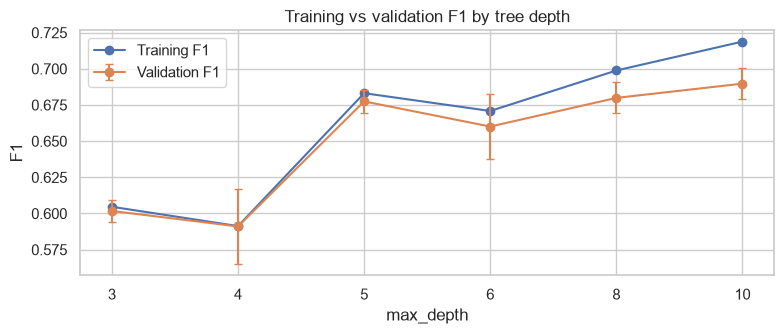

Best-scoring settings: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 50} | validation F1 0.690
Chosen settings:       {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 100} | validation F1 0.688 +/- 0.009
Training F1 0.708 vs validation 0.688 (gap 0.019)
Chosen tree depth: 10 | leaves: 234


Main model: deliberately limited depth-2 baseline, not the best model.
Baseline CV accuracy: 0.647
Baseline CV F1: 0.475
Baseline depth: 2 | leaves: 4


In [15]:
cvres = pd.DataFrame(res)
cvres["depth"] = [99 if p["max_depth"] is None else p["max_depth"] for p in cvres["params"]]
cvres["leaf"] = [p["min_samples_leaf"] for p in cvres["params"]]
cvres["weight"] = [str(p["class_weight"]) for p in cvres["params"]]

bp = tree_search.best_params_
curve = cvres[(cvres["leaf"] == bp["min_samples_leaf"]) & (cvres["weight"] == str(bp["class_weight"]))].sort_values("depth")
depth_labels = ["None" if d == 99 else str(d) for d in curve["depth"]]
plt.figure(figsize=(8, 3.5))
plt.plot(depth_labels, curve["mean_train_score"], marker="o", label="Training F1")
plt.errorbar(depth_labels, curve["mean_test_score"], yerr=curve["std_test_score"], marker="o", capsize=3, label="Validation F1")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Training vs validation F1 by tree depth")
plt.legend(); plt.tight_layout(); plt.show()

# One-standard-error rule: simplest settings within 1 SE of the best validation F1
best_row = cvres.loc[best]
limit = best_row["mean_test_score"] - best_row["std_test_score"] / np.sqrt(cv.get_n_splits())
eligible = cvres[cvres["mean_test_score"] >= limit]
chosen_idx = eligible.sort_values(["depth", "leaf"], ascending=[True, False]).index[0]
chosen = cvres.loc[chosen_idx]
tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **chosen["params"]).fit(X_train, y_train)

print("Best-scoring settings:", bp, f"| validation F1 {best_row['mean_test_score']:.3f}")
print("Chosen settings:      ", chosen["params"],
      f"| validation F1 {chosen['mean_test_score']:.3f} +/- {chosen['std_test_score']:.3f}")
print(f"Training F1 {chosen['mean_train_score']:.3f} vs validation {chosen['mean_test_score']:.3f} "
      f"(gap {chosen['mean_train_score'] - chosen['mean_test_score']:.3f})")
print("Chosen tree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())

# Keep the tuned tree; use a deliberately limited teaching baseline for the main results.
from sklearn.model_selection import cross_validate
tuned_tree = tree
tuned_chosen = chosen.copy()
BASE_SETTINGS = {"max_depth": 2, "class_weight": "balanced"}
base_template = DecisionTreeClassifier(random_state=RANDOM_STATE, **BASE_SETTINGS)
base_cv = cross_validate(base_template, X_train, y_train, cv=cv,
    scoring={"accuracy": "accuracy", "f1": "f1"}, return_train_score=True)
chosen = pd.Series({"params": BASE_SETTINGS,
    "mean_test_score": base_cv["test_f1"].mean(),
    "std_test_score": base_cv["test_f1"].std(ddof=0),
    "mean_train_score": base_cv["train_f1"].mean()})
tree = base_template.fit(X_train, y_train)
print("Main model: deliberately limited depth-2 baseline, not the best model.")
print("Baseline CV accuracy:", round(base_cv["test_accuracy"].mean(), 3))
print("Baseline CV F1:", round(base_cv["test_f1"].mean(), 3))
print("Baseline depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())


### 3.3 Test the simple base tree
Report actual scores. The limited tree prioritises recall; compare its accuracy with always-wait and the tuned tree.


              precision    recall  f1-score   support

 not yet (0)      0.971     0.595     0.738     13169
   water (1)      0.323     0.916     0.478      2783

    accuracy                          0.651     15952
   macro avg      0.647     0.755     0.608     15952
weighted avg      0.858     0.651     0.692     15952



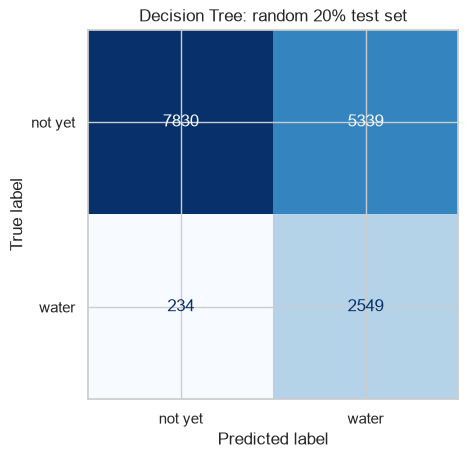

TP = 2549, TN = 7830, FP = 5339, FN = 234
Accuracy  = (TP + TN) / total     = (2549 + 7830) / 15952 = 0.651
Precision = TP / (TP + FP)        = 2549 / 7888 = 0.323
Recall    = TP / (TP + FN)        = 2549 / 2783 = 0.916
F1        = 2PR / (P + R)         = 0.478
Missed waterings (FN): 234 of 2783 days labelled as needing water (8.4%).


In [16]:
y_pred_tree = tree.predict(X_test)

print(classification_report(y_test, y_pred_tree, target_names=["not yet (0)", "water (1)"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tree),
                       display_labels=["not yet", "water"]).plot(cmap="Blues", colorbar=False)
plt.title("Decision Tree: random 20% test set"); plt.show()


tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tree).ravel()
acc = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp) if tp + fp else 0.0
rec = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}")
print(f"Accuracy  = (TP + TN) / total     = ({tp} + {tn}) / {tp + tn + fp + fn} = {acc:.3f}")
print(f"Precision = TP / (TP + FP)        = {tp} / {tp + fp} = {prec:.3f}")
print(f"Recall    = TP / (TP + FN)        = {tp} / {tp + fn} = {rec:.3f}")
print(f"F1        = 2PR / (P + R)         = {f1:.3f}")
assert np.isclose(f1, f1_score(y_test, y_pred_tree)), "Hand calculation does not match scikit-learn."
print(f"Missed waterings (FN): {fn} of {tp + fn} days labelled as needing water ({fn / (tp + fn):.1%}).")


### 3.4 Read the tree
Inspect feature importance and decision paths.


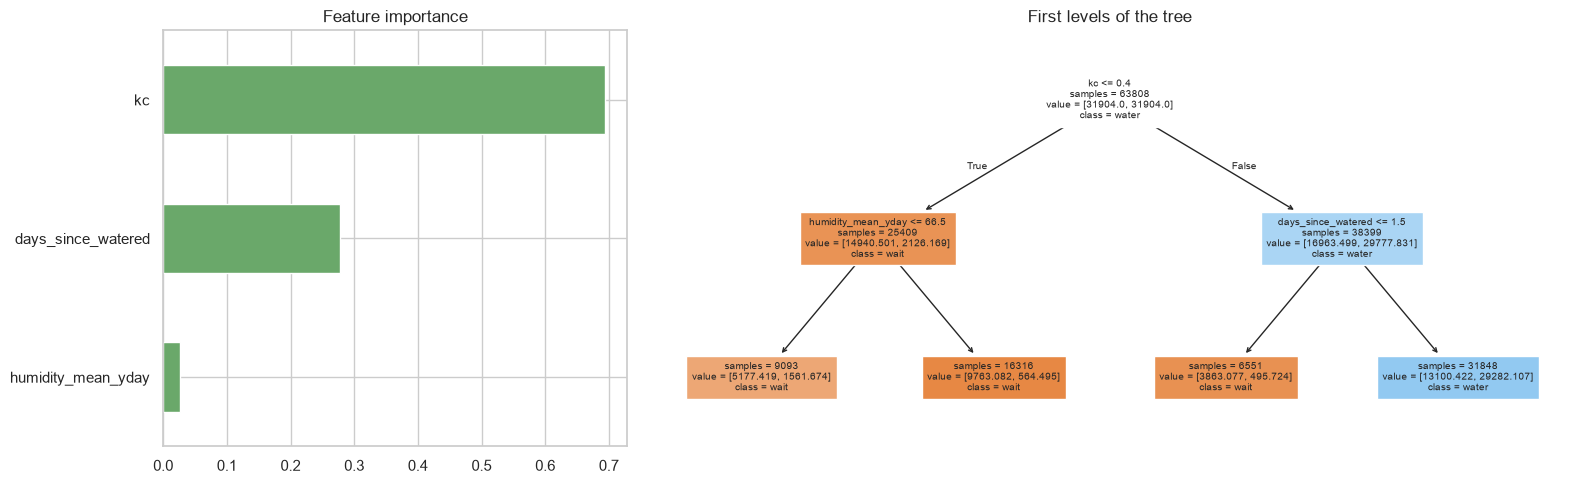

In [17]:
importance = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})
importance[importance > 0].plot(kind="barh", ax=axes[0], color="#6aa86a")
axes[0].set_title("Feature importance")
plot_tree(tree, feature_names=FEATURES, class_names=["wait", "water"],
          filled=True, max_depth=2, fontsize=7, ax=axes[1], impurity=False)
axes[1].set_title("First levels of the tree")
plt.tight_layout(); plt.show()


### 3.5 Compare models and check stability
Use matching splits and folds. Scale within LR/KNN pipelines. Compare calendar and always-wait baselines. The label-generating rule is perfect by construction.


Logistic Regression best settings: {'model__C': 1, 'model__class_weight': 'balanced'}


K-Nearest Neighbours best settings: {'model__n_neighbors': 15, 'model__weights': 'distance'}


Random Forest best settings: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 20}


,Accuracy,Balanced accuracy,Precision,Recall,F1,CV F1 mean,CV F1 std
Decision Tree,0.651,0.755,0.323,0.916,0.478,0.475,0.006
Tuned Decision Tree,0.903,0.794,0.775,0.626,0.692,0.688,0.009
Logistic Regression,0.766,0.797,0.416,0.845,0.557,0.554,0.004
K-Nearest Neighbours,0.859,0.693,0.638,0.439,0.520,0.518,0.007
Random Forest,0.851,0.880,0.544,0.923,0.684,0.686,0.008
Chosen fixed calendar,0.672,0.550,0.226,0.362,0.278,NaN,NaN
Always do not water,0.826,0.500,0.000,0.000,0.000,NaN,NaN
Hidden-parameter label rule (reference),1.000,1.000,1.000,1.000,1.000,NaN,NaN


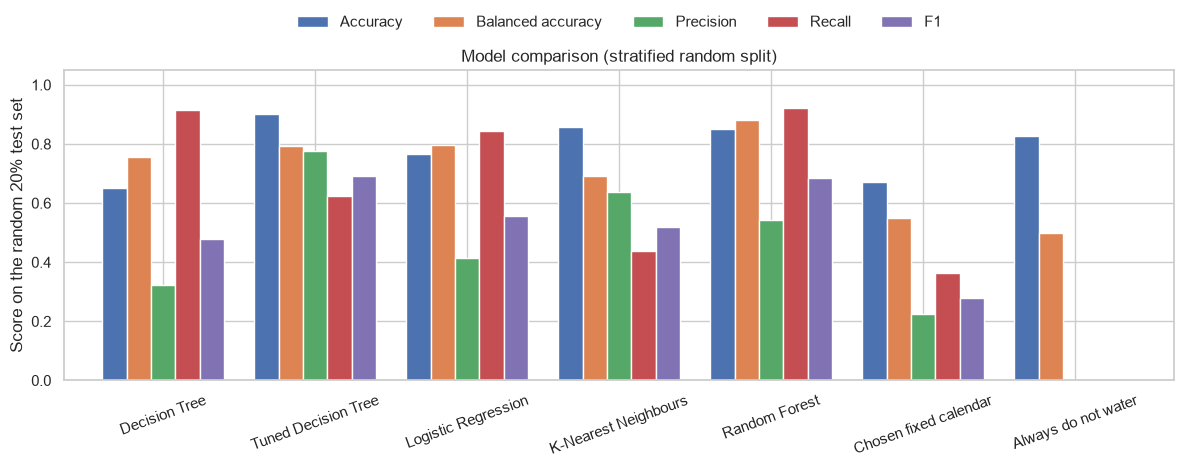

In [18]:
from sklearn.metrics import balanced_accuracy_score

candidates = {
    "Logistic Regression": (Pipeline([("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "K-Nearest Neighbours": (Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [15, 31, 61], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=2),
        {"max_depth": [6, 10], "min_samples_leaf": [5, 20], "class_weight": [None, "balanced"]})}
fitted = {"Decision Tree": tree, "Tuned Decision Tree": tuned_tree}
cv_f1 = {"Decision Tree": (chosen["mean_test_score"], chosen["std_test_score"]),
         "Tuned Decision Tree": (tuned_chosen["mean_test_score"], tuned_chosen["std_test_score"])}
for model_name, (model, grid) in candidates.items():
    search = GridSearchCV(model, grid, scoring="f1", cv=cv, n_jobs=2, error_score="raise").fit(X_train, y_train)
    fitted[model_name] = search.best_estimator_
    i = search.best_index_
    cv_f1[model_name] = (search.cv_results_["mean_test_score"][i], search.cv_results_["std_test_score"][i])
    print(model_name, "best settings:", search.best_params_)

def scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

predictions = {name: m.predict(X_test) for name, m in fitted.items()}
predictions["Chosen fixed calendar"] = test["calendar_pred"].to_numpy()
predictions["Always do not water"] = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train).predict(X_test)
# The rule with the plant's TRUE values made the labels, so it is perfect by construction.
# The app can never know those true values; it is shown only as the upper bound.
predictions["Hidden-parameter label rule (reference)"] = (test["deficit_mm"] >= test["true_threshold_mm"]).astype(int).to_numpy()
assert np.array_equal(predictions["Hidden-parameter label rule (reference)"], y_test.to_numpy())

results = pd.DataFrame({name: scores(y_test, p) for name, p in predictions.items()}).T
results["CV F1 mean"] = [cv_f1[n][0] if n in cv_f1 else np.nan for n in results.index]
results["CV F1 std"] = [cv_f1[n][1] if n in cv_f1 else np.nan for n in results.index]
display(results.round(3))
results.to_csv("model_comparison.csv")

results.drop(index="Hidden-parameter label rule (reference)")[["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(12, 5), rot=20, width=0.8)
plt.ylim(0, 1.05); plt.ylabel("Score on the random 20% test set")
plt.title("Model comparison (stratified random split)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=5, frameon=False)
plt.tight_layout(); plt.show()


**Chronological check:** tune through 2022; test on 2023-2025.


In [19]:
early = data[data["date"].dt.year <= 2022]
late = data[data["date"].dt.year >= 2023]
year_cv = []
for validation_year in range(2018, 2023):
    a = np.flatnonzero((early["date"].dt.year < validation_year).to_numpy())
    b = np.flatnonzero((early["date"].dt.year == validation_year).to_numpy())
    assert early.iloc[a]["date"].max() < early.iloc[b]["date"].min()
    year_cv.append((a, b))
year_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
    scoring="f1", cv=year_cv, n_jobs=2, return_train_score=True, error_score="raise")
year_search.fit(early[FEATURES], early[TARGET])
yr = pd.DataFrame(year_search.cv_results_)
yr["depth"] = [p["max_depth"] for p in yr["params"]]
yr["leaf"] = [p["min_samples_leaf"] for p in yr["params"]]
yb = yr.loc[year_search.best_index_]
ylimit = yb["mean_test_score"] - yb["std_test_score"] / np.sqrt(len(year_cv))
ychosen = yr[yr["mean_test_score"] >= ylimit].sort_values(["depth", "leaf"], ascending=[True, False]).iloc[0]
year_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **ychosen["params"]).fit(early[FEATURES], early[TARGET])
year_tuned_tree = year_tree
year_tuned_pred = year_tuned_tree.predict(late[FEATURES])
year_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **BASE_SETTINGS).fit(early[FEATURES], early[TARGET])
year_pred = year_tree.predict(late[FEATURES])
print("Chronological-only selected settings:", ychosen["params"])
split_check = pd.DataFrame({"Random 80/20": scores(y_test, y_pred_tree),
                            "Base tree: 2015-2022 train / 2023-2025 test": scores(late[TARGET], year_pred),
                            "Tuned tree: 2015-2022 train / 2023-2025 test": scores(late[TARGET], year_tuned_pred)}).T
display(split_check.round(3))
split_check.to_csv("chronological_comparison.csv")
print("Always-wait random-test accuracy:", round(results.loc["Always do not water", "Accuracy"], 3))
print("Similarity across these two splits alone does not prove generalisation to new plants or other climates.")


Chronological-only selected settings: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 100}


,Accuracy,Balanced accuracy,Precision,Recall,F1
Random 80/20,0.651,0.755,0.323,0.916,0.478
Base tree: 2015-2022 train / 2023-2025 test,0.650,0.750,0.325,0.904,0.478
Tuned tree: 2015-2022 train / 2023-2025 test,0.898,0.785,0.764,0.610,0.679


Always-wait random-test accuracy: 0.826
Similarity across these two splits alone does not prove generalisation to new plants or other climates.


### 3.6 Findings and next steps
The simple baseline sacrifices accuracy for recall. It is not the best model. Labels remain simulated; unseen-plant and field validation are still needed.


In [20]:
print("Main evaluation: stratified random 80/20")
for model_name in ["Decision Tree", "Tuned Decision Tree", "Random Forest", "Chosen fixed calendar", "Always do not water"]:
    row = results.loc[model_name]
    print(f"{model_name}: accuracy {row['Accuracy']:.1%}, balanced accuracy {row['Balanced accuracy']:.1%}, F1 {row['F1']:.3f}")
print("Chronological check: F1", round(f1_score(late[TARGET], year_pred), 3))
print("Scores measure synthetic-label agreement. The depth-2 base model is an intentionally limited demonstration; compare the tuned model before deployment.")


Main evaluation: stratified random 80/20
Decision Tree: accuracy 65.1%, balanced accuracy 75.5%, F1 0.478
Tuned Decision Tree: accuracy 90.3%, balanced accuracy 79.4%, F1 0.692
Random Forest: accuracy 85.1%, balanced accuracy 88.0%, F1 0.684
Chosen fixed calendar: accuracy 67.2%, balanced accuracy 55.0%, F1 0.278
Always do not water: accuracy 82.6%, balanced accuracy 50.0%, F1 0.000
Chronological check: F1 0.478
Scores measure synthetic-label agreement. The depth-2 base model is an intentionally limited demonstration; compare the tuned model before deployment.


## Appendix: Model files
JSON predictions are checked against Python. Kotlin and device testing remain pending.


In [21]:
import joblib
joblib.dump({"model": tree, "features": FEATURES, "versions": VERSIONS}, "decision_tree.joblib")
feature_units = ["C", "C", "%", "km/h", "mm", "mm", "mm", "mm", "days", "days", "ratio", "mm"]
# Exact definitions so the Android app computes the same inputs as training
FEATURE_DEFINITIONS = {'temp_mean_yday': "Yesterday's mean 2 m air temperature", 'temp_max_yday': "Yesterday's maximum 2 m air temperature", 'humidity_mean_yday': "Yesterday's mean relative humidity", 'wind_max_yday': "Yesterday's maximum 10 m wind speed", 'rain_yday': "Yesterday's raw precipitation, without the 2 mm filter", 'rain_last_3d': 'Raw precipitation sum over the three days before today, excluding today', 'et0_yday': "Yesterday's FAO reference evapotranspiration", 'et0_last_3d': 'ET0 sum over the three days before today, excluding today', 'days_since_rain': 'Consecutive days below 2 mm rain ending yesterday; 0 if yesterday had at least 2 mm, capped at 30 days', 'days_since_watered': 'Calendar days since the last WATERED check-in; model inputs start at 1; app handles watered-today separately', 'kc': 'Nominal group water-use coefficient from the species table', 'threshold_mm': 'Nominal group watering threshold from the species table'}
t = tree.tree_
exported = {"schema_version": 2, "features": FEATURES, "feature_units": feature_units,
    "classes": tree.classes_.tolist(), "input_dtype": "float32",
    "scope": "Morning-only history; simulated plant variation and imperfect gardener; synthetic labels from real Nairobi ERA5 weather",
    "children_left": t.children_left.tolist(), "children_right": t.children_right.tolist(),
    "feature": t.feature.tolist(), "threshold": t.threshold.tolist(),
    "feature_definitions": FEATURE_DEFINITIONS,
    "decision_day_inputs": "Use only yesterday and earlier, never decision-day weather. The app uses recent historical weather from its API; ERA5-to-app source differences need validation.",
    "tree_depth": int(tree.get_depth()), "n_leaves": int(tree.get_n_leaves()),
    "predicted_class": [int(tree.classes_[np.argmax(v[0])]) for v in t.value],
    "versions": VERSIONS, "weather_sha256": provenance["sha256"],
    "plant_parameters": plants.to_dict(orient="records"), "available_water_fraction": AVAILABLE_WATER,
    "min_effective_rain_mm": MIN_EFFECTIVE_RAIN, "rain_history_days": 30,
    "simulation": {"plants_per_group": PLANTS_PER_GROUP, "notice_probability": NOTICE_PROB,
                   "habit_probability": HABIT_PROB, "seed": RANDOM_STATE,
                   "kc_factor_range": [0.8, 1.2], "available_water_range": [0.10, 0.18],
                   "root_factor_range": [0.8, 1.2], "p_offset_range": [-0.1, 0.1]},
    "selected_parameters": chosen["params"], "model_role": "Deliberately limited depth-2 teaching baseline; not selected as best-performing model", "evaluation": "stratified random 80/20, separately tuned chronological check"}
Path("decision_tree.json").write_text(json.dumps(exported, indent=2))
# Reload the actual serialized representation and verify its traversal.
loaded = json.loads(Path("decision_tree.json").read_text())
def predict_export(row):
    row = np.asarray(row, dtype=np.float32)
    assert len(row) == len(FEATURES) and np.isfinite(row).all()
    node = 0
    while loaded["children_left"][node] != -1:
        f = loaded["feature"][node]
        node = loaded["children_left"][node] if float(row[f]) <= loaded["threshold"][node] else loaded["children_right"][node]
    return loaded["predicted_class"][node]
export_predictions = np.array([predict_export(row) for row in X_test.to_numpy()])
assert np.array_equal(export_predictions, y_pred_tree), "JSON predictions differ from the Python model."
Path("decision_tree_rules.txt").write_text(export_text(tree, feature_names=FEATURES,
                                                        max_depth=tree.get_depth(), decimals=17))
# Cover every fitted leaf using training rows, and both float32 sides of every split.
X_cover = X_train.to_numpy(dtype=np.float32)
_, first_rows = np.unique(tree.apply(X_train), return_index=True)
cases = [{"features": X_cover[i].astype(float).tolist(),
          "expected_class": int(tree.predict(pd.DataFrame(X_cover[i:i+1], columns=FEATURES))[0]),
          "kind": "leaf"} for i in sorted(first_rows)]
assert len(first_rows) == tree.get_n_leaves()
paths = tree.decision_path(X_train)
for node in np.flatnonzero(t.children_left != -1):
    source_row = paths[:, node].nonzero()[0][0]
    threshold = t.threshold[node]
    low = np.float32(threshold)
    if float(low) > threshold:
        low = np.nextafter(low, np.float32(-np.inf))
    high = np.nextafter(low, np.float32(np.inf))
    assert float(low) <= threshold < float(high)
    for kind, value in [("split_left", low), ("split_right", high)]:
        row = X_cover[source_row].copy()
        row[t.feature[node]] = value
        frame = pd.DataFrame(row.reshape(1, -1), columns=FEATURES)
        assert tree.decision_path(frame)[0, node] != 0
        cases.append({"features": row.astype(float).tolist(),
                      "expected_class": int(tree.predict(frame)[0]),
                      "kind": kind, "node": int(node)})
for case in cases:
    assert predict_export(case["features"]) == case["expected_class"], "Parity case fails JSON traversal."
Path("android_parity_cases.json").write_text(json.dumps({"feature_order": FEATURES, "cases": cases}, indent=2))
Path("run_versions.json").write_text(json.dumps({"python": platform.python_version(), "packages": VERSIONS}, indent=2))
print("JSON export matches all", len(X_test), "test predictions.")
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
print("Parity cases:", len(first_rows), "leaf cases +", len(cases) - len(first_rows), "split-boundary cases")
print("Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.")


JSON export matches all 15952 test predictions.
Depth: 2 Leaves: 4
Parity cases: 4 leaf cases + 6 split-boundary cases
Saved model, full rules, JSON, Android parity cases, comparison scores and runtime versions.


### Save the project files
Create the bundle below. Download the executed notebook separately: **File > Download > .ipynb**.


In [22]:
#@title Create the download bundle
import zipfile
Path("README.md").write_text('# SemProject_MLEngine\nSmart Watering | ICS 3202 CAT 2 | Build-bible update\n\n## Run\nOpen DecisionTree_Base.ipynb in Colab, choose Runtime > Run all, and save with outputs. The verified ERA5 snapshot is included inside the notebook, so no weather API download is needed. Its checksum is checked before use. The loader also saves the CSV and provenance for the appendix download bundle.\n\n## Presenters\nIan: data and cleaning. Devyan: labels and exploration. Alfred: training and results. Each has six presentation sections. Project ownership in the build bible remains Alfred (ML), Ian (Android), Devyan (research/presentation).\n\n## Data and target\nReal ERA5 Nairobi weather, 2015-2025, drives a synthetic scenario with 20 individuals across five groups. water_today predicts end-of-day simulated watering need from morning-available history. Hidden plant parameters and an imperfect gardener generate labels. These are not measured real-plant outcomes. Coefficients and root depths vary by +/-20%; available water is drawn from 0.10-0.18 and p varies by +/-0.1 within 0.2-0.8. NOTICE_PROB=0.5, HABIT_PROB=0.05, seed=42, four individuals per group. The probabilities are conditional: exactly 0.5 when needy, otherwise 0.05. They were not tuned to obtain any score band.\n\n## Inputs and Android contract\nThe 12 ordered features are temp_mean_yday, temp_max_yday, humidity_mean_yday, wind_max_yday, rain_yday, rain_last_3d, et0_yday, et0_last_3d, days_since_rain, days_since_watered, kc, threshold_mm. No decision-day weather enters a feature. Three-day sums exclude today. days_since_rain ends yesterday and is capped at 30 days to match the Kotlin weather window. days_since_watered comes from WATERED check-ins in the app. Nominal species thresholds remain 24.5, 21.0, 14.0, 9.8 and 18.9 mm. Full definitions and units are in decision_tree.json. Real app weather source differences still need validation.\n\n## Evaluation\nPrimary: stratified random 80/20 split and stratified five-fold CV on the training subset. The main Decision Tree is a deliberately limited depth-2, class-balanced teaching baseline chosen to demonstrate lower performance. It is not the best-performing model. Five-fold CV reports its actual accuracy and F1. A separate tuned tree uses the one-standard-error simplicity heuristic and remains in the comparison. Random rows can share weather and neighbouring dates, so this does not establish future or unseen-plant performance. Secondary: retune independently on 2015-2022 using expanding annual folds; test only on 2023-2025. No hyperparameters for this secondary check are selected using later years. Scaling remains inside pipelines. All classifiers, a fixed calendar, always-wait and the hidden-parameter generating rule are shown. The generating rule is perfect by construction and is not independent evidence. Report accuracy, balanced accuracy, precision, recall and F1 as obtained. The user requested a 60-70% accuracy demonstration. Model complexity was deliberately limited; data, labels and held-out scores were not altered. This does not justify choosing the weaker model for deployment.\n\n## Exports\nThe bundle contains raw weather and provenance, scores, chronological scores, plant scenario parameters, the Python model, schema-v2 JSON tree, full rules, parity cases and execution versions. Python validates JSON traversal on the entire random test set, every fitted leaf and both float32 sides of every split. These tests are not a Kotlin/device run. New exports must replace the old app assets together. Kotlin integration and field validation remain future work.\n\n## Source and submission\nPrepared from the supplied 5 November build-bible snapshot and realistic_eval_cells.py. Its linked live Claude artifact could not be retrieved here. The provided CAT 2 brief requires at least four EDA observations, explained cleaning, a validated base model and a further-validation plan. Publish the executed notebook in public SemProject_MLEngine by the stated 6 November 2026 due date; teammates fork it. No GitHub publication is implied by generating these files.\n\nSources: Open-Meteo historical weather API; Allen et al. (1998), FAO-56; WUCOLS context; scikit-learn documentation. Code and editing assistance: OpenAI Codex. Follow the actual course disclosure requirements.\n')
Path("requirements.txt").write_text('numpy>=1.26,<3\npandas>=2.2,<4\nmatplotlib>=3.8,<4\nseaborn>=0.13,<1\nscikit-learn>=1.5,<2\nrequests>=2.31,<3\njoblib>=1.3,<2\n')
individuals.to_csv("simulated_plants.csv", index=False)
bundle_files = ["README.md", "requirements.txt", "nairobi_era5_daily_2015_2025.csv",
    "weather_provenance.json", "simulated_plants.csv", "model_comparison.csv", "chronological_comparison.csv",
    "decision_tree.joblib", "decision_tree.json", "decision_tree_rules.txt", "android_parity_cases.json", "run_versions.json"]
with zipfile.ZipFile("SmartWatering_Artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in bundle_files:
        bundle.write(filename)
print("Saved SmartWatering_Artifacts.zip. Save this executed notebook separately.")


Saved SmartWatering_Artifacts.zip. Save this executed notebook separately.


### Sources
- [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api)
- [FAO-56: Allen et al. (1998)](https://www.fao.org/4/X0490E/X0490E00.htm)
- [WUCOLS](https://ucanr.edu/sites/WUCOLS/)
- [Scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data)

Code/editing assistance: OpenAI Codex.
